<a href="https://colab.research.google.com/github/Ariqq16/PCVK_Ganjil_2026/blob/main/P7/week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood
from sklearn.cluster import KMeans

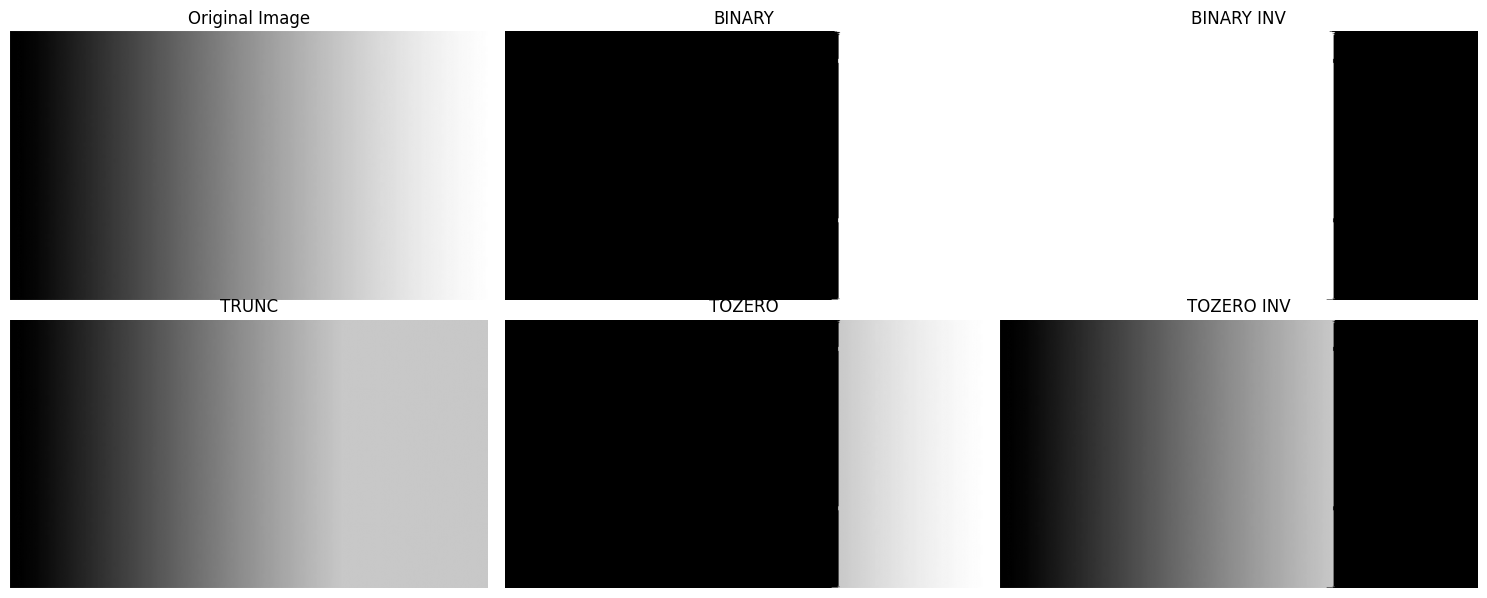

In [2]:
from google.colab import drive
BASE_PATH = ""

filename = BASE_PATH + '/content/drive/MyDrive/PCVK_2026/gradient.jpg'
img_gray = cv.imread(filename, cv.IMREAD_GRAYSCALE)

if img_gray is None:
    try:
        img_gray = cv.cvtColor(cv.imread(BASE_PATH + 'lena.jpg'), cv.COLOR_BGR2GRAY)
    except:
        img_gray = np.tile(np.arange(256, dtype=np.uint8), (256, 1))

thresh = 200
maxval = 255

# 1. BINARY: piksel > thresh -> maxval, else 0
binary = np.where(img_gray > thresh, maxval, 0).astype(np.uint8)

# 2. BINARY_INV: piksel > thresh -> 0, else maxval
binary_inv = np.where(img_gray > thresh, 0, maxval).astype(np.uint8)

# 3. TRUNC: piksel > thresh -> thresh, else tetap
trunc = np.where(img_gray > thresh, thresh, img_gray).astype(np.uint8)

# 4. TOZERO: piksel > thresh -> tetap, else 0
tozero = np.where(img_gray > thresh, img_gray, 0).astype(np.uint8)

# 5. TOZERO_INV: piksel > thresh -> 0, else tetap
tozero_inv = np.where(img_gray > thresh, 0, img_gray).astype(np.uint8)

# Hasil
titles = ['Original Image', 'BINARY', 'BINARY INV', 'TRUNC', 'TOZERO', 'TOZERO INV']
images = [img_gray, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(15, 6))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

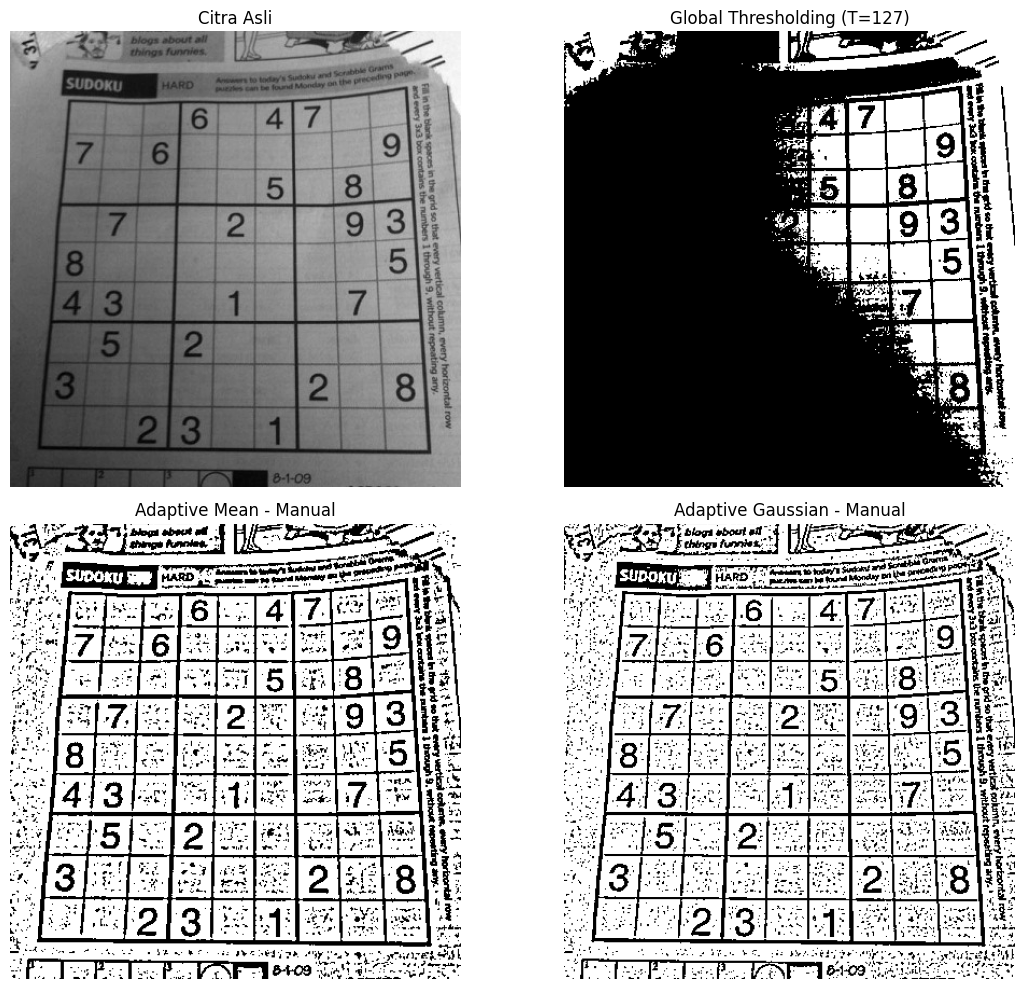

In [3]:
img_sudoku = cv.imread(BASE_PATH + '/content/drive/MyDrive/PCVK_2026/sudoku-original.jpg', cv.IMREAD_GRAYSCALE)

if img_sudoku is None:
    img_sudoku = cv.imread(BASE_PATH + 'sudoku.jpg', cv.IMREAD_GRAYSCALE)

# Global Threshold Manual (T=127)
global_thresh = np.where(img_sudoku > 127, 255, 0).astype(np.uint8)

# Parameter Adaptive Threshold Manual
block_size = 11
C = 2
sigma = 2
pad = block_size // 2
padded_img = np.pad(img_sudoku, ((pad, pad), (pad, pad)), mode='reflect').astype(np.float32)

# Kernel Gaussian 11x11
ax = np.linspace(-(pad), pad, block_size)
gauss_1d = np.exp(-0.5 * np.square(ax / sigma))
gauss_2d = np.outer(gauss_1d, gauss_1d)
gauss_kernel = gauss_2d / np.sum(gauss_2d)

H, W = img_sudoku.shape
adaptive_mean = np.zeros((H, W), dtype=np.uint8)
adaptive_gauss = np.zeros((H, W), dtype=np.uint8)

for y in range(H):
    for x in range(W):
        window = padded_img[y:y+block_size, x:x+block_size]

        # Adaptive Mean
        mean_val = np.mean(window)
        adaptive_mean[y, x] = 255 if img_sudoku[y, x] > (mean_val - C) else 0

        # Adaptive Gaussian
        gauss_val = np.sum(window * gauss_kernel)
        adaptive_gauss[y, x] = 255 if img_sudoku[y, x] > (gauss_val - C) else 0

titles_ad = ['Citra Asli', 'Global Thresholding (T=127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
imgs_ad = [img_sudoku, global_thresh, adaptive_mean, adaptive_gauss]

plt.figure(figsize=(12, 10))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(imgs_ad[i], cmap='gray')
    plt.title(titles_ad[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

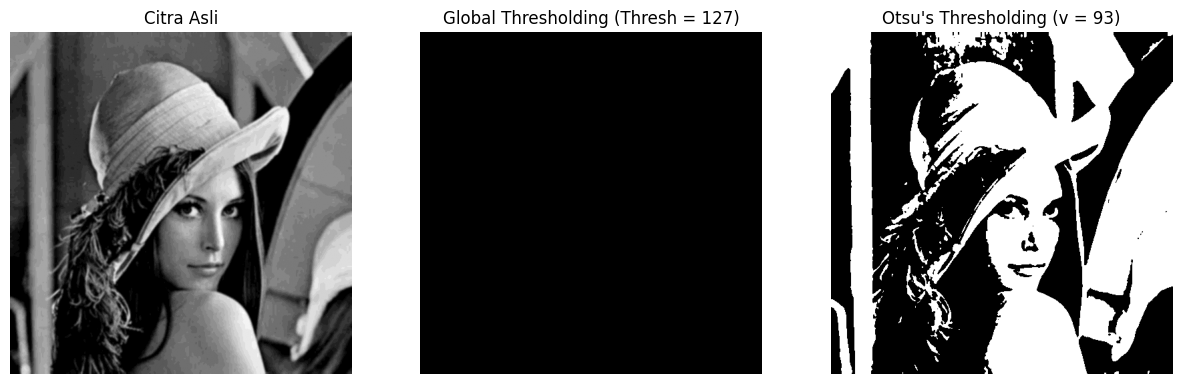

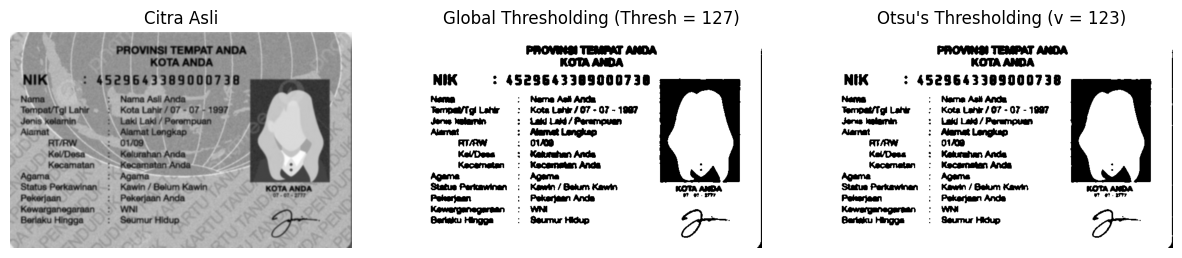

In [4]:
def otsu_manual(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    hist, bins = np.histogram(gray, bins=np.arange(0, 257))

    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in range(1, 256):
        pcb = np.sum(hist[:t])
        pcf = np.sum(hist[t:])

        if pcb == 0 or pcf == 0:
            continue

        Wb = pcb / float(pixel_number)
        Wf = pcf / float(pixel_number)

        mub = np.sum(intensity_arr[:t] * hist[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * hist[t:]) / float(pcf)

        value = Wb * Wf * ((mub - muf) ** 2)

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = np.zeros_like(gray)
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

img_lena_lc = cv.imread(BASE_PATH + '/content/drive/MyDrive/PCVK_2026/lena_gs_lc2.jpg', cv.IMREAD_GRAYSCALE)
if img_lena_lc is None:
    img_lena_lc = cv.imread(BASE_PATH + '/content/drive/MyDrive/PCVK_2026/lena.jpg', cv.IMREAD_GRAYSCALE)

if img_lena_lc is None:
    print("Error: File gambar Lena tidak ditemukan. Pastikan 'lena_gs_lc2.jpg' atau 'lena.jpg' ada di direktori Anda.")
else:
    blur_lena = cv.GaussianBlur(img_lena_lc, (5, 5), 0)
    glob_lena = np.where(blur_lena > 127, 255, 0).astype(np.uint8)
    otsu_lena, t_lena = otsu_manual(blur_lena)

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1); plt.imshow(blur_lena, cmap='gray'); plt.title('Citra Asli'); plt.axis('off')
    plt.subplot(1, 3, 2); plt.imshow(glob_lena, cmap='gray'); plt.title('Global Thresholding (Thresh = 127)'); plt.axis('off')
    plt.subplot(1, 3, 3); plt.imshow(otsu_lena, cmap='gray'); plt.title(f"Otsu's Thresholding (v = {t_lena})"); plt.axis('off')
    plt.show()

img_ktp = cv.imread(BASE_PATH + '/content/drive/MyDrive/PCVK_2026/ktp.jpg', cv.IMREAD_GRAYSCALE)
if img_ktp is None:
    img_ktp = cv.imread(BASE_PATH + '/content/drive/MyDrive/PCVK_2026/ktp_fulan.jpg', cv.IMREAD_GRAYSCALE)

if img_ktp is None:
    print("Error: File gambar KTP tidak ditemukan. Pastikan 'ktp.jpeg' atau 'ktp_fulan.jpg' ada di direktori Anda.")
else:
    blur_ktp = cv.GaussianBlur(img_ktp, (5, 5), 0)
    glob_ktp = np.where(blur_ktp > 127, 255, 0).astype(np.uint8)
    otsu_ktp, t_ktp = otsu_manual(blur_ktp)

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1); plt.imshow(blur_ktp, cmap='gray'); plt.title('Citra Asli'); plt.axis('off')
    plt.subplot(1, 3, 2); plt.imshow(glob_ktp, cmap='gray'); plt.title('Global Thresholding (Thresh = 127)'); plt.axis('off')
    plt.subplot(1, 3, 3); plt.imshow(otsu_ktp, cmap='gray'); plt.title(f"Otsu's Thresholding (v = {t_ktp})"); plt.axis('off')
    plt.show()

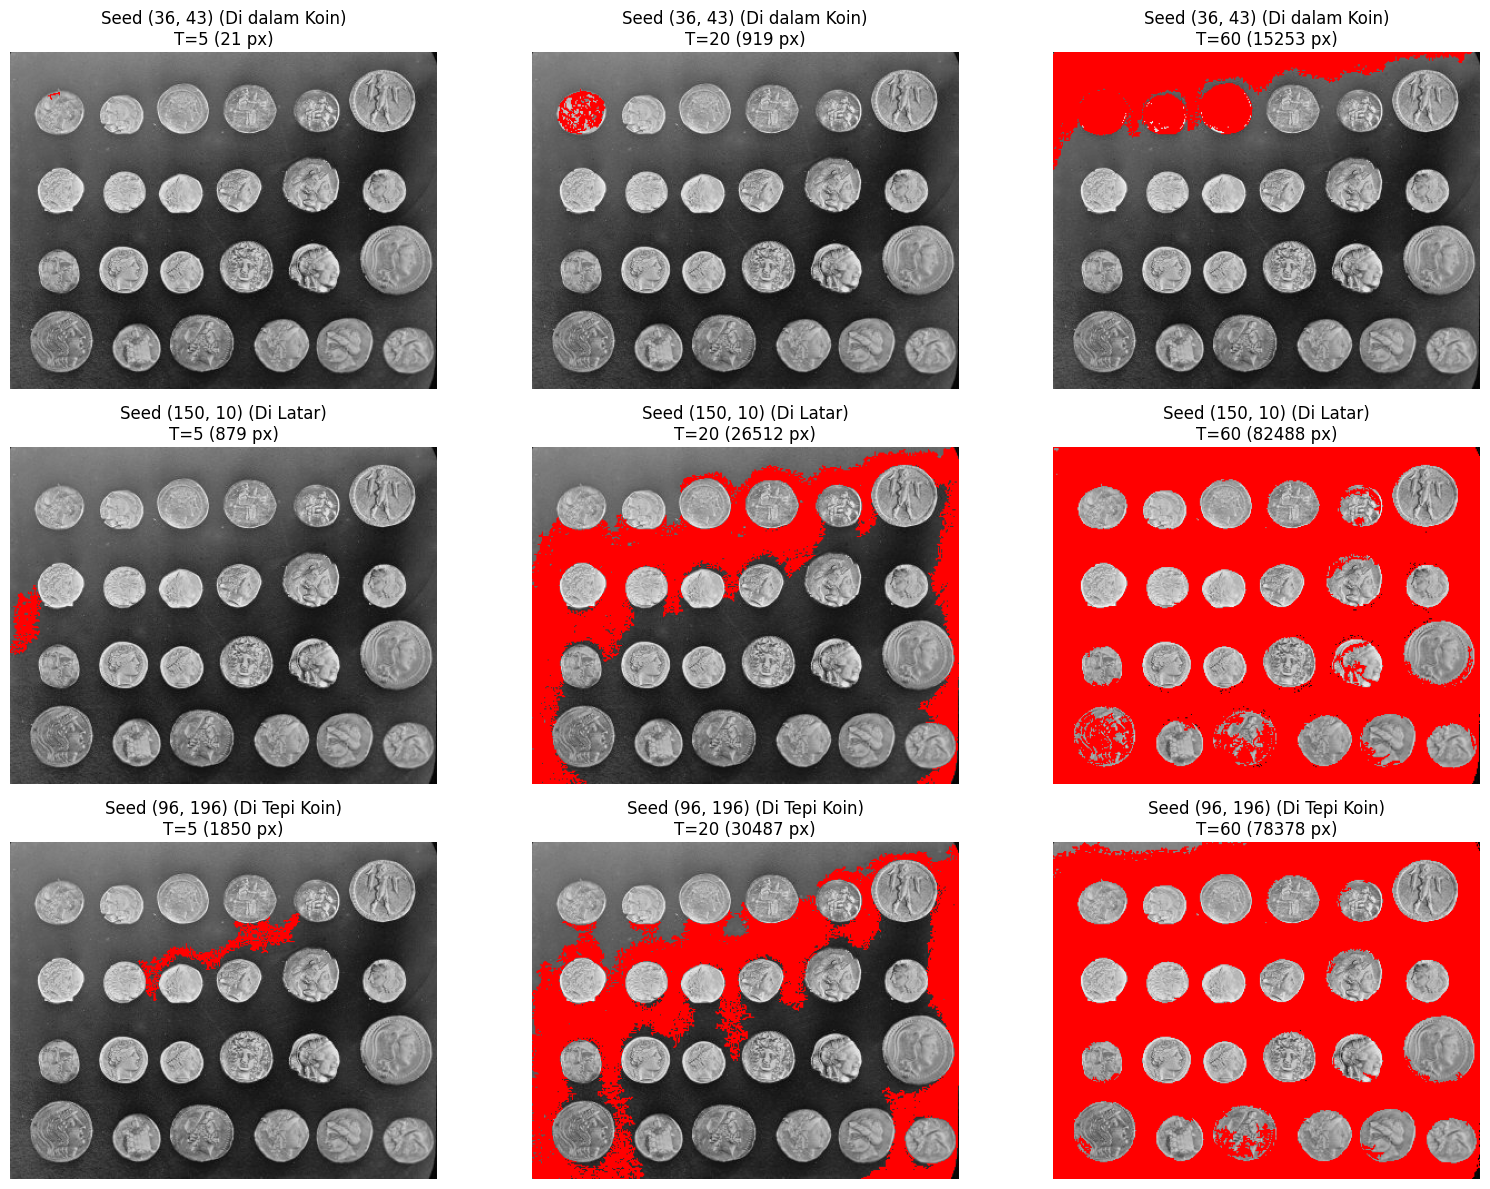

In [5]:
img_coins = data.coins()

seeds = [(36, 43), (150, 10), (96, 196)]
seeds_name = ['Di dalam Koin', 'Di Latar', 'Di Tepi Koin']
thresholds = [5, 20, 60]

plt.figure(figsize=(16, 12))
plot_idx = 1

for idx, seed in enumerate(seeds):
    seed_val = img_coins[seed[0], seed[1]]

    for T in thresholds:
        visited = np.zeros_like(img_coins, dtype=bool)
        region_mask = np.zeros_like(img_coins, dtype=bool)
        queue = deque([seed])
        visited[seed[0], seed[1]] = True

        H_c, W_c = img_coins.shape

        while queue:
            r, c = queue.popleft()
            region_mask[r, c] = True

            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                nr, nc = r + dr, c + dc
                if 0 <= nr < H_c and 0 <= nc < W_c and not visited[nr, nc]:
                    if abs(int(img_coins[nr, nc]) - int(seed_val)) <= T:
                        visited[nr, nc] = True
                        queue.append((nr, nc))
        coins_rgb = cv.cvtColor(img_coins, cv.COLOR_GRAY2RGB)
        coins_rgb[region_mask] = [255, 0, 0] # Warna Merah

        plt.subplot(3, 3, plot_idx)
        plt.imshow(coins_rgb)
        plt.title(f"Seed {seed} ({seeds_name[idx]})\nT={T} ({np.sum(region_mask)} px)")
        plt.axis('off')
        plot_idx += 1

plt.tight_layout()
plt.show()

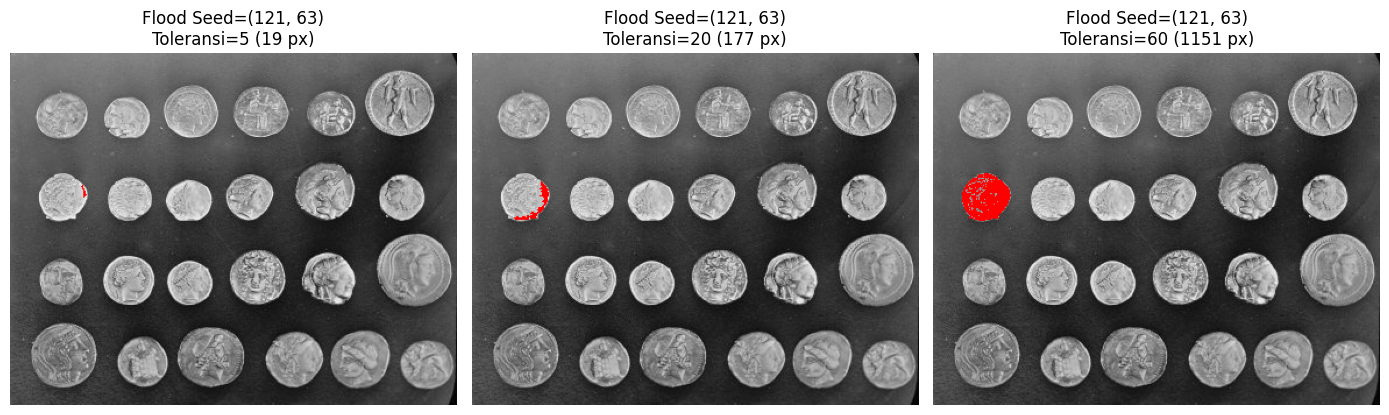

In [6]:
gray_c = data.coins()
seed_pt = (121, 63)

plt.figure(figsize=(14, 4))

for i, tol in enumerate([5, 20, 60], 1):
    mask_flood = flood(gray_c, seed_point=seed_pt, tolerance=tol, connectivity=1)

    vis_flood = cv.cvtColor(gray_c, cv.COLOR_GRAY2RGB)
    vis_flood[mask_flood] = [255, 0, 0]

    plt.subplot(1, 3, i)
    plt.imshow(vis_flood)
    plt.title(f"Flood Seed={seed_pt}\nToleransi={tol} ({np.sum(mask_flood)} px)")
    plt.axis('off')

plt.tight_layout()
plt.show()

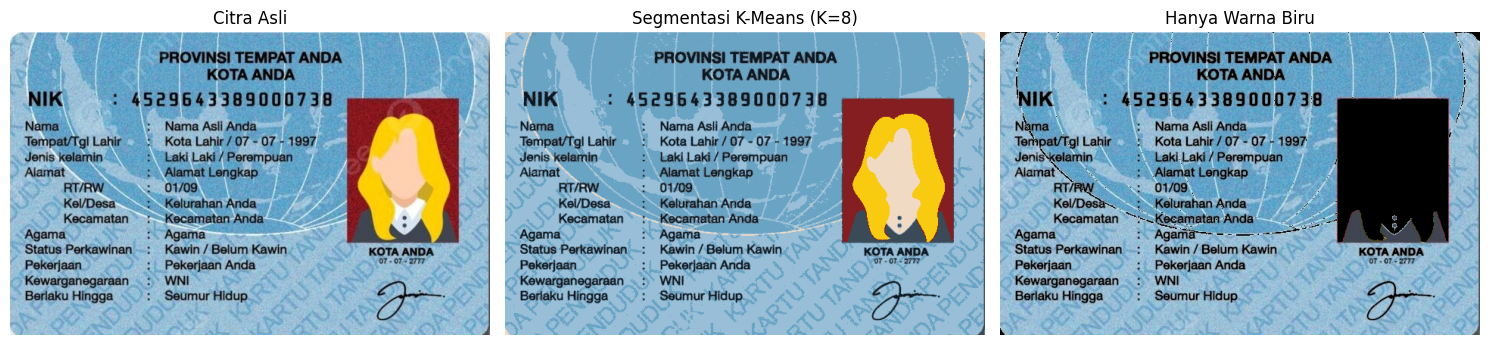

In [7]:
ktp_color = cv.imread(BASE_PATH + '/content/drive/MyDrive/PCVK_2026/ktp.jpg')
if ktp_color is None:
    ktp_color = cv.imread(BASE_PATH + '/content/drive/MyDrive/PCVK_2026/ktp_fulan.jpg')

ktp_rgb = cv.cvtColor(ktp_color, cv.COLOR_BGR2RGB)

X_pixels = ktp_rgb.reshape((-1, 3)).astype(np.float32)
kmeans = KMeans(n_clusters=8, random_state=42, n_init=10).fit(X_pixels)
segmented_pixels = kmeans.cluster_centers_[kmeans.labels_].astype(np.uint8)
img_kmeans = segmented_pixels.reshape(ktp_rgb.shape)

hsv = cv.cvtColor(img_kmeans, cv.COLOR_RGB2HSV)

lower_blue = np.array([85, 25, 40])
upper_blue = np.array([130, 255, 255])
blue_mask = cv.inRange(hsv, lower_blue, upper_blue)

only_blue = cv.bitwise_and(ktp_rgb, ktp_rgb, mask=blue_mask)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(ktp_rgb)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_kmeans)
plt.title('Segmentasi K-Means (K=8)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(only_blue)
plt.title('Hanya Warna Biru')
plt.axis('off')

plt.tight_layout()
plt.show()